<a href="https://colab.research.google.com/github/Ayesh2002/ml-student-dropout/blob/RF/02_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 01. Import libraries

In [1]:
# Data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

# Data splitting and model validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Random Forest model
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Fixed seed for reproducibility
SEED = 42

print("Libraries imported successfully.")
print("scikit-learn version:", sklearn.__version__)

Libraries imported successfully.
scikit-learn version: 1.6.1


##2. Load and preview the dataset

In [2]:
# Dataset URL
DATA_URL = (
    "https://raw.githubusercontent.com/Ayesh2002/ml-student-dropout/"
    "5d932c6ff712451a084f57a6dd2df39fb6277890/data/student_dropout_academic_.csv"
)

# Load the dataset
df = pd.read_csv(DATA_URL)

# Display its dimensions
print("Dataset shape:", df.shape)

# Preview the first five records
df.head()

Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


##3. Check dataset structure and quality

In [3]:
# Inspect column names and data types
df.info()

# Check missing values
print("\nTotal missing values:", df.isna().sum().sum())

# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# Check the number of students in each target class
print("\nTarget class distribution:")
print(df["Target"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nationality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

##4. Separate the target and split the data

In [4]:
# Separate input features and target
X = df.drop(columns="Target").copy()
y = df["Target"].copy()

# Split while keeping similar class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (3539, 36)
Test data shape: (885, 36)


##5. EDA: Explore the training class distribution

          Students  Percentage
Target                        
Graduate      1767       49.93
Dropout       1137       32.13
Enrolled       635       17.94


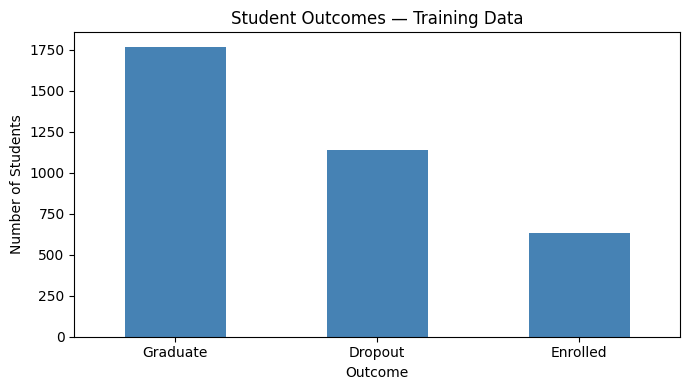

In [5]:
# Summarise the training target classes
class_counts = y_train.value_counts()

class_summary = pd.DataFrame({
    "Students": class_counts,
    "Percentage": (class_counts / len(y_train) * 100).round(2)
})

print(class_summary)

# Plot the class distribution
class_counts.plot(
    kind="bar",
    figsize=(7, 4),
    color="steelblue",
    rot=0
)

plt.title("Student Outcomes — Training Data")
plt.xlabel("Outcome")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

##6. Measure baseline performance using training cross-validation

In [ ]:
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=SEARCH_JOBS,
    error_score="raise",
)

baseline_summary = pd.Series(
    {
        "Training accuracy": baseline_cv["train_accuracy"].mean(),
        **{
            f"CV {metric}": baseline_cv[f"test_{metric}"].mean()
            for metric in scoring
        },
    },
    name="Original RF",
)

display(baseline_summary.round(4).to_frame())
baseline_summary.to_csv(RESULTS / "baseline_cv.csv")

,Original RF
Training accuracy,1.0000
CV accuracy,0.7720
CV macro_f1,0.6761
CV balanced_accuracy,0.6677
CV dropout_recall,0.7695


##7. Tune Random Forest

In [ ]:
base_params = {
    "rf__max_depth": None,
    "rf__min_samples_leaf": 1,
    "rf__max_features": "sqrt",
    "rf__class_weight": None,
    "prep__cat__encoder__min_frequency": None,
}

space = {
    "rf__max_depth": [None, 10, 20, 30],
    "rf__min_samples_leaf": [1, 2, 4, 8],
    "rf__max_features": ["sqrt", 0.3, 0.5, 0.8, 1.0],
    "rf__class_weight": [None, "balanced", "balanced_subsample"],
    "prep__cat__encoder__min_frequency": [None, 10, 30],
}

candidates = [
    base_params,
    {
        **base_params,
        "rf__max_features": 0.5,
    },
    {
        **base_params,
        "rf__max_features": 0.5,
        "rf__min_samples_leaf": 4,
        "rf__class_weight": "balanced_subsample",
    },
] + list(
    ParameterSampler(
        space,
        n_iter=9,
        random_state=SEED,
    )
)

grid = [
    {key: [value] for key, value in params.items()}
    for params in candidates
]

search = GridSearchCV(
    baseline,
    param_grid=grid,
    scoring=scoring,
    refit="accuracy",
    cv=cv,
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    return_train_score=True,
    error_score="raise",
    verbose=1,
)

search.fit(X_train, y_train)

print("Selected settings:", search.best_params_)
print("Selected tuning-CV accuracy:", round(search.best_score_, 4))

cv_results = pd.DataFrame(search.cv_results_)

columns = [
    "rank_test_accuracy",
    "mean_train_accuracy",
    "mean_test_accuracy",
    "mean_test_macro_f1",
    "mean_test_dropout_recall",
    "params",
]

display(
    cv_results[columns]
    .sort_values("rank_test_accuracy")
    .head()
)

cv_results[columns].to_csv(
    RESULTS / "tuning_cv.csv",
    index=False,
)

assert (
    search.best_score_
    >= baseline_cv["test_accuracy"].mean() - 1e-12
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Selected settings: {'prep__cat__encoder__min_frequency': None, 'rf__class_weight': 'balanced', 'rf__max_depth': 30, 'rf__max_features': 0.3, 'rf__min_samples_leaf': 2}
Selected tuning-CV accuracy: 0.7731


,rank_test_accuracy,mean_train_accuracy,mean_test_accuracy,mean_test_macro_f1,mean_test_dropout_recall,params
10,1,0.986578,0.773100,0.710555,0.747554,"{'prep__cat__encoder__min_frequency': None, 'r..."
11,2,0.995055,0.772250,0.699075,0.754602,"{'prep__cat__encoder__min_frequency': 10, 'rf_..."
0,3,1.000000,0.771972,0.676083,0.769534,"{'prep__cat__encoder__min_frequency': None, 'r..."
8,4,0.972097,0.771403,0.693473,0.751959,"{'prep__cat__encoder__min_frequency': None, 'r..."
1,5,1.000000,0.770840,0.693605,0.758973,"{'prep__cat__encoder__min_frequency': None, 'r..."


##8. Freeze the selected model and inspect overfitting

In [ ]:
baseline_model = clone(baseline).set_params(
    rf__oob_score=True,
    rf__n_jobs=-1,
).fit(X_train, y_train)

selected_model = clone(search.best_estimator_).set_params(
    rf__oob_score=True,
    rf__n_jobs=-1,
).fit(X_train, y_train)

diagnostics = pd.DataFrame([
    {
        "Model": name,
        "Training accuracy": model.score(X_train, y_train),
        "OOB accuracy": model.named_steps["rf"].oob_score_,
    }
    for name, model in [
        ("Original RF", baseline_model),
        ("Selected RF", selected_model),
    ]
]).set_index("Model")

display(diagnostics.round(4))
diagnostics.to_csv(RESULTS / "training_diagnostics.csv")

frozen = {
    "run_id": RUN_ID,
    "prediction_time": "after first semester",
    "features": features,
    "target_classes": ["Dropout", "Enrolled", "Graduate"],
    "dataset_url": DATA_URL,
    "dataset_sha256": hashlib.sha256(data_bytes).hexdigest(),
    "seed": SEED,
    "test_size": 0.20,
    "selection_metric": "accuracy",
    "cv_folds": 5,
    "selected_parameters": search.best_params_,
    "tuning_cv_accuracy": float(search.best_score_),
    "sklearn_version": sklearn.__version__,
    "holdout_status": "Previously explored benchmark",
    "benchmark_evaluated": False,
}

print("Selected model frozen.")
print("Benchmark evaluation remains disabled below.")

,Training accuracy,OOB accuracy
Model,,
Original RF,1.0000,0.7683
Selected RF,0.9864,0.7768


Selected model frozen.
Benchmark evaluation remains disabled below.


##9. Evaluate the frozen models

In [ ]:
RUN_BENCHMARK = False

if not RUN_BENCHMARK:
    print(
        "Benchmark evaluation is OFF. "
        "Finish training-only model selection first."
    )

else:
    rows = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, (name, model) in zip(
        axes,
        [
            ("Original RF", baseline_model),
            ("Selected RF", selected_model),
        ],
    ):
        pred = model.predict(X_test)

        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro-F1": f1_score(y_test, pred, average="macro"),
            "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        })

        print("\n" + name)
        print(
            classification_report(
                y_test,
                pred,
                digits=3,
                zero_division=0,
            )
        )

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            pred,
            labels=["Dropout", "Enrolled", "Graduate"],
            ax=ax,
            cmap="Blues",
            colorbar=False,
        )
        ax.set_title(name)

    plt.tight_layout()
    plt.show()

    test_results = pd.DataFrame(rows).set_index("Model")
    display(test_results.round(4))

    test_results.to_csv(RESULTS / "benchmark_results.csv")

    frozen["benchmark_evaluated"] = True
    frozen["selected_benchmark_accuracy"] = float(
        test_results.loc["Selected RF", "Accuracy"]
    )

Benchmark evaluation is OFF. Finish training-only model selection first.


##10. Save the model and results

In [ ]:
joblib.dump(
    selected_model,
    RESULTS / "random_forest.joblib",
)

(RESULTS / "experiment.json").write_text(
    json.dumps(frozen, indent=2),
    encoding="utf-8",
)

split_record = pd.concat([
    pd.DataFrame({
        "Dataset row": X_train.index,
        "Partition": "training",
    }),
    pd.DataFrame({
        "Dataset row": X_test.index,
        "Partition": "benchmark",
    }),
]).sort_values("Dataset row")

split_record.to_csv(
    RESULTS / "student_split.csv",
    index=False,
)

print("Saved model and results to:", RESULTS)

Saved model and results to: rf_results/b4716dbf
